# EMQA_L2_horizon_naive

**Forecast error grows with the age of the information, except at the weekly lag**

Energy Markets Quantitative Analysis (EMQA), Lecture 2 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L2/EMQA_L2_horizon_naive/EMQA_L2_horizon_naive.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# course chart style: transparent background, no grid, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}   # fixed colour per entity


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=ncol, bbox_to_anchor=(0.5, y),
                   frameon=False, handlelength=2.0, columnspacing=1.2)

## Data and cut-off

In [3]:
TZ = "Europe/Brussels"
PD = pd.read_csv(DATA + "power_da_prices_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
_hydro = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", usecols=["date_cet", "hydro_run_of_river"],
                     parse_dates=["date_cet"]).set_index("date_cet")["hydro_run_of_river"]
# cut-off = last complete month covered by the prices and the Romanian generation data
_raw_last = min(PD["RO"].dropna().index.max(), _hydro.dropna().index.max())
END = pd.Timestamp(((_raw_last + pd.Timedelta(days=1)).to_period("M").to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp("2022-01-01")
N_TEST, N_BURN = 365, 182                                  # test year; burn-in (its forecasts only feed QRA, CP, HS)
TEST0 = END - pd.Timedelta(days=N_TEST - 1)
FC0 = TEST0 - pd.Timedelta(days=N_BURN)
FDAYS = pd.date_range(FC0, END, freq="D")                  # burn-in + test days
TDAYS = pd.date_range(TEST0, END, freq="D")                # test days
print("cut-off:", END.date(), "| test year:", TEST0.date(), "to", END.date())

cut-off: 2026-10-31 | test year: 2025-11-01 to 2026-10-31


## Price panel

In [4]:
def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


HP = pd.read_csv(DATA + "power_da_prices_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "RO"])
PM, DST = day_matrix(HP["RO"].dropna())
CAL = pd.date_range(START, END, freq="D")
PM, DST = PM.reindex(CAL), DST.reindex(CAL)
assert not PM.isna().any().any(), "panel has gaps"
P_ = PM.values.astype(float)
DOW = CAL.dayofweek.values
IDX = {t: i for i, t in enumerate(CAL)}
TI_ROWS = np.array([IDX[t] for t in TDAYS])              # panel rows of the test days
A = P_[TI_ROWS]                                          # actual prices of the test year, days x 24
# naive benchmark: same hour of d-7 on Monday, Saturday, Sunday, of d-1 otherwise
NAIVE = np.array([P_[i - 7] if DOW[i] in (0, 5, 6) else P_[i - 1] for i in TI_ROWS])
print("panel:", CAL[0].date(), "to", CAL[-1].date(), len(CAL), "days x 24 hours")

panel: 2022-01-01 to 2026-10-31 1765 days x 24 hours


## MAE of the forecast $\hat P_{d,h}=P_{d-k,h}$ on the test year

In [5]:
hz = {k: float(np.mean(np.abs(A - P_[TI_ROWS - k]))) for k in range(1, 15)}
for k, v in hz.items():
    print(f"k = {k:2d}: MAE {v:.2f} EUR/MWh")

k =  1: MAE 29.37 EUR/MWh
k =  2: MAE 38.52 EUR/MWh
k =  3: MAE 40.53 EUR/MWh
k =  4: MAE 41.47 EUR/MWh
k =  5: MAE 42.31 EUR/MWh
k =  6: MAE 38.86 EUR/MWh
k =  7: MAE 34.41 EUR/MWh
k =  8: MAE 39.77 EUR/MWh
k =  9: MAE 44.46 EUR/MWh
k = 10: MAE 45.45 EUR/MWh
k = 11: MAE 45.65 EUR/MWh
k = 12: MAE 45.77 EUR/MWh
k = 13: MAE 42.54 EUR/MWh
k = 14: MAE 38.94 EUR/MWh


## The chart

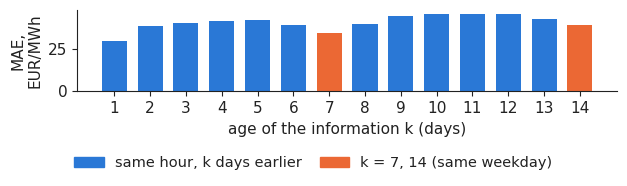

In [6]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(6.4, 1.9))
ks = list(range(1, 15))
ax.bar(ks, [hz[k] for k in ks], color=[PAL["DE_LU"] if k % 7 == 0 else PAL["RO"] for k in ks], width=0.7)
hnd = [Patch(color=PAL["RO"], label="same hour, k days earlier"), Patch(color=PAL["DE_LU"], label="k = 7, 14 (same weekday)")]
ax.set_xticks(ks)
ax.set_xlabel("age of the information k (days)")
ax.set_ylabel("MAE,\nEUR/MWh")
legend_bottom(fig, handles=hnd, labels=[h.get_label() for h in hnd], ncol=2)
fig.tight_layout(rect=(0, 0.16, 1, 1))
plt.savefig('horizon_naive.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()

In [7]:
print("Numbers on the slide")
print(f'  MAE k = 1: {hz[1]:.2f}')
print(f'  MAE k = 2: {hz[2]:.2f}')
print(f'  MAE k = 3: {hz[3]:.2f}')
print(f'  MAE k = 4: {hz[4]:.2f}')
print(f'  MAE k = 5: {hz[5]:.2f}')
print(f'  MAE k = 6: {hz[6]:.2f}')
print(f'  MAE k = 7: {hz[7]:.2f}')
print(f'  MAE k = 8: {hz[8]:.2f}')
print(f'  MAE k = 9: {hz[9]:.2f}')
print(f'  MAE k = 10: {hz[10]:.2f}')
print(f'  MAE k = 11: {hz[11]:.2f}')
print(f'  MAE k = 12: {hz[12]:.2f}')
print(f'  MAE k = 13: {hz[13]:.2f}')
print(f'  MAE k = 14: {hz[14]:.2f}')

Numbers on the slide
  MAE k = 1: 29.37
  MAE k = 2: 38.52
  MAE k = 3: 40.53
  MAE k = 4: 41.47
  MAE k = 5: 42.31
  MAE k = 6: 38.86
  MAE k = 7: 34.41
  MAE k = 8: 39.77
  MAE k = 9: 44.46
  MAE k = 10: 45.45
  MAE k = 11: 45.65
  MAE k = 12: 45.77
  MAE k = 13: 42.54
  MAE k = 14: 38.94
